In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

In [3]:

csv_path = Path("station_day.csv")
raw = pd.read_csv(csv_path, parse_dates=["Date"])

features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene",
]

print("Размер исходной таблицы", raw.shape)
print("Доля пропусков по показателям, %")
print(raw[features + ["Xylene"]].isna().mean().mul(100).round(1))

Размер исходной таблицы (108035, 16)
Доля пропусков по показателям, %
PM2.5      20.0
PM10       39.5
NO         15.8
NO2        15.3
NOx        14.3
NH3        44.5
CO         12.0
SO2        23.3
O3         23.7
Benzene    29.1
Toluene    35.8
Xylene     78.8
dtype: float64


In [4]:
unique = raw.drop_duplicates()
clean = unique.dropna(subset=features).reset_index(drop=True)

X_raw = clean[features]
y_true = clean["AQI_Bucket"]

print("Удалено дубликатов", len(raw) - len(unique))
print("Удалено строк с пропусками в признаках", len(unique) - len(clean))
print("Осталось наблюдений и признаков", X_raw.shape)
print("Распределение категорий после очистки")
print(y_true.value_counts(dropna=False))

Удалено дубликатов 0
Удалено строк с пропусками в признаках 71471
Осталось наблюдений и признаков (36564, 11)
Распределение категорий после очистки
AQI_Bucket
Moderate        12939
Satisfactory     8396
Very Poor        4922
Poor             4893
Severe           2520
Good             2062
NaN               832
Name: count, dtype: int64


In [5]:
X_raw

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92
1,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50
2,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95
3,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63
4,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02
...,...,...,...,...,...,...,...,...,...,...,...
36559,17.03,39.64,3.23,11.42,14.65,18.98,0.57,11.39,31.76,0.79,6.85
36560,9.79,19.87,23.51,16.50,40.02,25.09,0.66,10.34,30.19,0.93,6.37
36561,18.60,32.26,13.65,200.87,214.20,11.40,0.78,5.12,38.17,3.52,8.64
36562,16.07,39.30,7.56,29.13,36.69,29.26,0.69,5.88,29.64,1.86,8.40


In [6]:
y_true

0                 NaN
1            Moderate
2            Moderate
3            Moderate
4            Moderate
             ...     
36559    Satisfactory
36560            Good
36561    Satisfactory
36562    Satisfactory
36563    Satisfactory
Name: AQI_Bucket, Length: 36564, dtype: str

In [7]:
display(X_raw.corr().round(2))

means = X_raw.mean()
scales = X_raw.std(ddof=0).replace(0, 1)
X = (X_raw - means) / scales

print("Размер матрицы для кластеризации", X.shape)
print("Пропусков в матрице", X.isna().sum().sum())
display(X.head())

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
PM2.5,1.00,0.86,0.59,0.56,0.58,0.53,0.64,0.32,0.16,0.14,0.36
PM10,0.86,1.00,0.61,0.55,0.60,0.51,0.62,0.37,0.01,0.13,0.36
NO,0.59,0.61,1.00,0.65,0.87,0.42,0.65,0.29,0.04,0.19,0.35
NO2,0.56,0.55,0.65,1.00,0.76,0.40,0.56,0.37,0.26,0.12,0.28
NOx,0.58,0.60,0.87,0.76,1.00,0.44,0.62,0.33,0.13,0.18,0.29
NH3,0.53,0.51,0.42,0.40,0.44,1.00,0.44,0.26,0.13,0.05,0.22
CO,0.64,0.62,0.65,0.56,0.62,0.44,1.00,0.35,0.13,0.13,0.35
SO2,0.32,0.37,0.29,0.37,0.33,0.26,0.35,1.00,0.19,0.05,0.21
O3,0.16,0.01,0.04,0.26,0.13,0.13,0.13,0.19,1.00,-0.01,0.05
Benzene,0.14,0.13,0.19,0.12,0.18,0.05,0.13,0.05,-0.01,1.00,0.51


Размер матрицы для кластеризации (36564, 11)
Пропусков в матрице 0


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,-0.138418,-0.404412,-0.633033,-0.692831,-0.723052,-0.812522,-1.184415,-0.217304,1.251983,-0.306216,-0.460879
1,-0.010788,-0.337689,-0.641071,-0.697805,-0.729315,-0.882929,-1.161437,0.257432,1.593691,-0.303984,-0.442995
2,-0.049942,-0.302916,-0.645738,-0.515439,-0.675095,-0.904003,-1.138460,1.499377,1.408751,-0.302496,-0.398283
3,0.082772,-0.255181,-0.507279,-0.354625,-0.539642,-0.778037,-1.172926,2.201945,1.300853,-0.297288,-0.408150
4,-0.229690,-0.493326,-0.612030,-0.446802,-0.632815,-0.849402,-1.195904,0.655872,1.806229,-0.306216,-0.488632


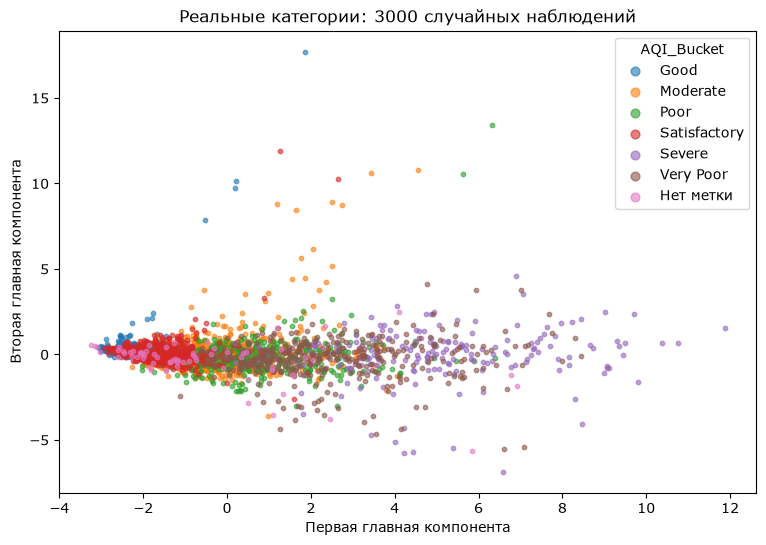

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

demo = clean.sample(n=3000, random_state=42).copy()

values = StandardScaler().fit_transform(demo[features])
demo[["PC1", "PC2"]] = PCA(n_components=2).fit_transform(values)
demo["Категория"] = demo["AQI_Bucket"].fillna("Нет метки")

plt.figure(figsize=(9, 6))

for category, group in demo.groupby("Категория"):
    plt.scatter(
        group["PC1"], group["PC2"],
        label=category, s=10, alpha=0.6,
    )

plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Реальные категории: 3000 случайных наблюдений")
plt.legend(title="AQI_Bucket", markerscale=2)
plt.show()

### K-means

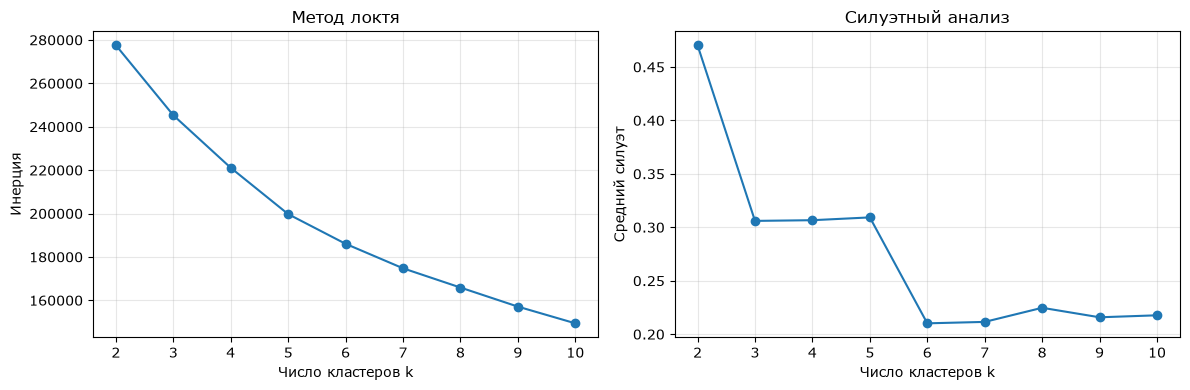

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Проверяем k от 2 до 10 включительно.
k_values = range(2, 11)


inertias = []
scores = {}


for k in k_values:
    # Для каждого k один раз вызываем fit(X) и используем полученное
    # разбиение для расчёта обеих метрик.
    model = KMeans(
        n_clusters=k,      # Сколько кластеров должна найти модель.
        init="k-means++",  # Начальные центры стараемся выбирать дальше друг от друга.
        n_init=10,         # Внутри fit пробуем 10 инициализаций и берём минимум инерции.
        random_state=42,   # Фиксируем случайность, чтобы повторить результат.
    ).fit(X)

    # Инерция — сумма квадратов расстояний от каждой точки до центра
    # её кластера. Она рассчитана по всему X. На графике ищем «локоть»:
    # место, после которого добавление кластеров даёт заметно меньший выигрыш.
    inertias.append(model.inertia_)

    # Расчёт опирается на попарные расстояния, поэтому для экономии времени
    # берём 3000 строк. При том же порядке строк X и том же random_state
    # в расчёт для каждого k попадают одни и те же строки.
    # Модель при этом обучена на всём X.
    scores[k] = silhouette_score(
        X, model.labels_, sample_size=3000, random_state=42
    )


silhouettes = pd.Series(scores, name="Средний силуэт").rename_axis("k")

fig, (ax_elbow, ax_silhouette) = plt.subplots(1, 2, figsize=(12, 4))

ax_elbow.plot(k_values, inertias, marker="o")
ax_elbow.set(title="Метод локтя", ylabel="Инерция")


ax_silhouette.plot(silhouettes.index, silhouettes, marker="o")
ax_silhouette.set(title="Силуэтный анализ", ylabel="Средний силуэт")

for ax in (ax_elbow, ax_silhouette):
    ax.set(xlabel="Число кластеров k", xticks=list(k_values))
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

###  Тестирование различных инициализаций K-means при фиксированном числе кластеров k.

In [24]:
# Фиксируем k, найденное на предыдущем этапе, чтобы сравнить
# влияние способа выбора начальных центров при одном числе кластеров.
k = 3

# random выбирает начальные центры случайно из строк X.
# k-means++ даёт больший шанс точкам, удалённым от уже выбранных центров.
initializations = ["k-means++", "random"]

# Для каждого способа используем 10 значений seed, от 42 до 51.
# Это позволяет оценить, насколько результат зависит от случайного старта.
seeds = range(42, 52)
runs = []
partitions = []

for init in initializations:
    for seed in seeds:
        # Один fit соответствует одной попытке с данным способом и seed.
        # n_init=1 сохраняет результат этой попытки без отбора лучшего
        # разбиения из нескольких стартов внутри fit.
        model = KMeans(
            n_clusters=k,
            init=init,
            n_init=1,
            random_state=seed,
        ).fit(X)

        # Сохраняем метки всех строк для последующего ансамбля.
        # Порядок разбиений в partitions совпадает с порядком строк в results.
        partitions.append(model.labels_.copy())

        # Модель обучается на всём X. Для расчёта силуэта берём 3000 строк,
        # чтобы сократить число вычисляемых попарных расстояний.
        # Фиксированный random_state здесь даёт одну подвыборку для всех запусков.
        silhouette = silhouette_score(
            X, model.labels_, sample_size=3000, random_state=42
        )

        # Инерция ниже у более компактных кластеров. Силуэт выше, когда
        # объекты близки к своему кластеру и хорошо отделены от соседнего.
        # n_iter_ показывает, сколько итераций алгоритм сделал до остановки.
        runs.append({
            "init": init,
            "seed": seed,
            "inertia": model.inertia_,
            "silhouette": silhouette,
            "iterations": model.n_iter_,
        })

results = pd.DataFrame(runs)

# Сводим 10 запусков отдельно для каждого способа инициализации.
# min показывает лучшую достигнутую инерцию, mean — средний результат,
# а std — насколько значения метрики менялись от запуска к запуску.
summary = results.groupby("init").agg(
    inertia_min=("inertia", "min"),
    inertia_mean=("inertia", "mean"),
    inertia_std=("inertia", "std"),
    silhouette_mean=("silhouette", "mean"),
    silhouette_std=("silhouette", "std"),
    iterations_mean=("iterations", "mean"),
)

display(summary.round({
    "inertia_min": 2, "inertia_mean": 2, "inertia_std": 2,
    "silhouette_mean": 4, "silhouette_std": 4,
    "iterations_mean": 2,
}))

,inertia_min,inertia_mean,inertia_std,silhouette_mean,silhouette_std,iterations_mean
init,,,,,,
k-means++,245276.49,246945.50,3518.25,0.3391,0.0697,16.8
random,245276.29,245277.21,0.38,0.3057,0.0009,20.1


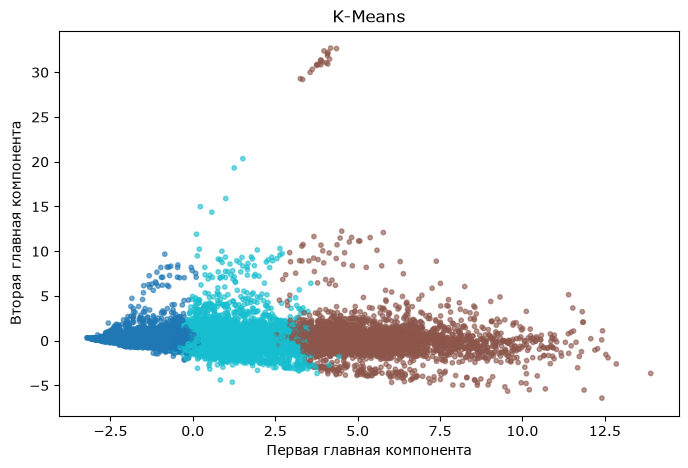

In [25]:
# Берём один запуск K-Means с минимальной инерцией.
labels_kmeans = partitions[int(results["inertia"].idxmin())]
X_kmeans_2d = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_kmeans_2d[:, 0], X_kmeans_2d[:, 1],
    c=labels_kmeans, cmap="tab10", s=10, alpha=0.6,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("K-Means")
plt.show()

##### Количество объектов в кластерах K-Means.


In [ ]:

# labels_kmeans.sizes()
sizes = pd.Series(labels_kmeans).value_counts()
sizes

0    22196
2    10892
1     3476
Name: count, dtype: int64

In [26]:
results

,init,seed,inertia,silhouette,iterations
0,k-means++,42,245276.774597,0.307172,19
1,k-means++,43,245277.389202,0.305120,21
2,k-means++,44,245277.421703,0.305120,20
3,k-means++,45,253440.545273,0.469798,10
4,k-means++,46,253797.464439,0.472823,9
5,k-means++,47,245277.389202,0.305120,21
6,k-means++,48,245277.389202,0.305120,21
7,k-means++,49,245276.784382,0.307172,17
8,k-means++,50,245276.487874,0.306759,16
9,k-means++,51,245277.347623,0.307172,14


### Ансамблевая кластеризация K-means

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Ограничиваем подвыборку 3000 объектами, так как дальше сравниваем все пары.
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=min(3000, len(X)), replace=False)
X_sample = X.iloc[sample_idx]

# Берём метки одних и тех же объектов из каждого запуска K-Means.
# Строка — объект, столбец — запуск.
ensemble_predictions = np.column_stack([
    labels[sample_idx] for labels in partitions
])

In [ ]:
n_samples = len(X_sample)
co_association = np.zeros((n_samples, n_samples), dtype=np.float32)

for labels in ensemble_predictions.T:
    # Даём паре один голос, если в этом запуске оба объекта попали
    # в один кластер. Сравнения внутри запуска учитывают только совпадение меток.
    same_cluster = labels[:, None] == labels[None, :]
    co_association += same_cluster

# Согласие — доля запусков, в которых пара оказалась в одном кластере.
co_association /= len(partitions)

# Чем чаще пара попадала в один кластер, тем меньше расстояние между объектами.
distance_matrix = 1 - co_association

In [31]:
distance_matrix

array([[0. , 1. , 1. , ..., 1. , 1. , 0.9],
       [1. , 0. , 0. , ..., 0. , 0. , 1. ],
       [1. , 0. , 0. , ..., 0. , 0. , 1. ],
       ...,
       [1. , 0. , 0. , ..., 0. , 0. , 1. ],
       [1. , 0. , 0. , ..., 0. , 0. , 1. ],
       [0.9, 1. , 1. , ..., 1. , 1. , 0. ]],
      shape=(3000, 3000), dtype=float32)

In [33]:
# Используем готовую матрицу расстояний. На каждом шаге сливаем два кластера
# с наименьшим средним расстоянием между их объектами, пока не останется k.
consensus = AgglomerativeClustering(
    n_clusters=k,
    metric="precomputed",
    linkage="average",
)

ensemble_labels = consensus.fit_predict(distance_matrix)

print("Размеры кластеров", np.bincount(ensemble_labels))

Размеры кластеров [ 898  296 1806]


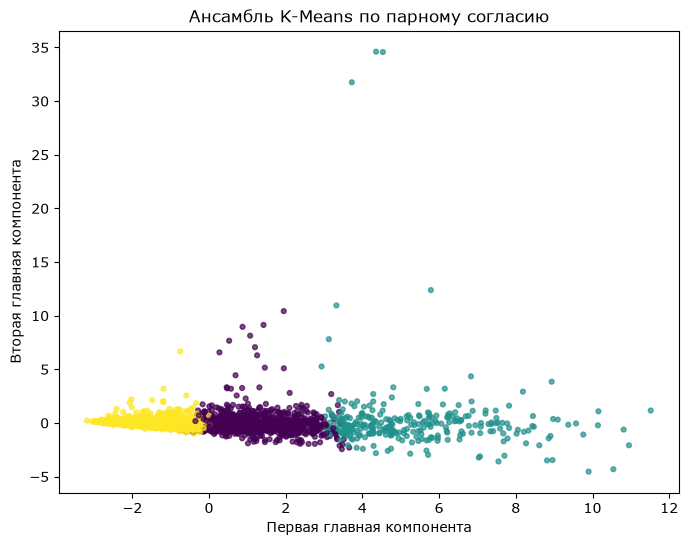

In [32]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# PCA даёт две координаты для графика. Цвет задают итоговые метки ансамбля.
X_2d = PCA(n_components=2).fit_transform(X_sample)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=ensemble_labels, cmap="viridis", s=12, alpha=0.7,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Ансамбль K-Means по парному согласию")
plt.show()

### DBSCAN

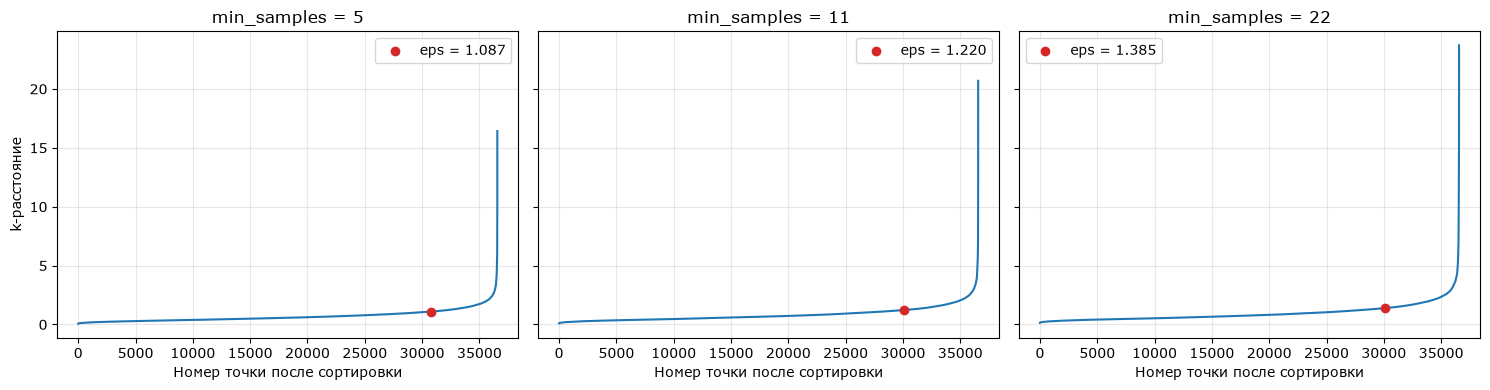

,min_samples,eps,Кластеров,"Покрытие, %",Силуэт
0,5,1.087,43,88.368,0.119
1,11,1.220,11,88.437,0.385
2,22,1.385,2,89.320,0.580


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, silhouette_score

db_candidates = []
dbscan_labels = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for min_samples, ax in zip([5, 11, 22], axes):
    neighbors = NearestNeighbors(
        n_neighbors=min_samples,
        metric="euclidean",
    ).fit(X)

    # При запросе kneighbors(X) сама точка входит в число соседей,
    # как и в DBSCAN. Последнее расстояние — минимальный радиус,
    # при котором точка набирает min_samples и становится ядром
    distances, _ = neighbors.kneighbors(X)
    k_distances = np.sort(distances[:, -1])

    # 2. Исключаем верхний 1% расстояний только из поиска локтя.
    body = k_distances[:int(0.99 * len(k_distances))]

    # 3. Автоматически находим локоть.
    # Нормируем обе оси до [0, 1]. Кандидат на локоть — точка,
    # где кривая сильнее всего уходит вниз от прямой между её концами.
    if body[-1] > body[0]:
        positions = np.linspace(0, 1, len(body))
        scaled_distances = (body - body[0]) / (body[-1] - body[0])
        knee = int(np.argmax(positions - scaled_distances))
    else:
        knee = 0

    # Берём расстояние в точке перегиба в исходном масштабе.
    eps = max(float(body[knee]), np.finfo(float).eps)

     # Применяем выбранный радиус ко всему X с той же метрикой расстояния.
    labels = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean",
    ).fit_predict(X)

    dbscan_labels[min_samples] = labels

    # 5. Рассчитываем показатели без учёта шума.
    # Метка -1 обозначает шум. Покрытие — доля всех объектов,
    # которым DBSCAN назначил кластер.
    assigned = labels != -1
    n_assigned = int(assigned.sum())
    n_clusters = np.unique(labels[assigned]).size
    coverage = assigned.mean()

     # Считаем силуэт только по объектам в кластерах.
    # Для расчёта нужно от 2 до n_assigned - 1 кластеров.
    score = np.nan
    if 2 <= n_clusters < n_assigned:
        score = silhouette_score(
            X[assigned],
            labels[assigned],
            metric="euclidean",
        )

    db_candidates.append({
        "min_samples": min_samples,
        "eps": eps,
        "Кластеров": n_clusters,
        "Покрытие, %": coverage * 100,
        "Силуэт": score,
    })

    # 6. Отмечаем выбранный eps на соответствующем графике.
    ax.plot(k_distances)
    ax.scatter(
        knee,
        eps,
        color="tab:red",
        zorder=3,
        label=f"eps = {eps:.3f}",
    )
    ax.set_title(f"min_samples = {min_samples}")
    ax.set_xlabel("Номер точки после сортировки")
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_ylabel("k-расстояние")
fig.tight_layout()
plt.show()

# Общая таблица для трёх вариантов.
db_table = pd.DataFrame(db_candidates)
display(db_table.round(3))

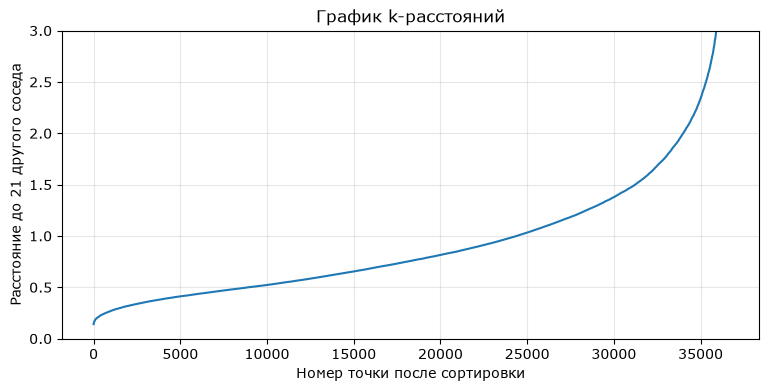

In [37]:
min_samples = 22

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean",
).fit(X)

distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0, 3)
plt.xlabel("Номер точки после сортировки")
plt.ylabel("Расстояние до 21 другого соседа")
plt.title("График k-расстояний")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
rows = []
labels_by_eps = {}

for eps in [1.5, 1.4, 1.6]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    labels_by_eps[eps] = labels

    noise = labels == -1
    sizes = pd.Series(labels[~noise]).value_counts()

    rows.append({
        "eps": eps,
        "Число кластеров": len(sizes),
        "Шум, %": round(100 * noise.mean(), 2),
        "Размер крупнейшего кластера": sizes.max(),
        "Размеры": sizes.to_dict()
    })

display(pd.DataFrame(rows))

,eps,Число кластеров,"Шум, %",Размер крупнейшего кластера,Размеры
0,1.5,3,8.58,33381,"0 33381 2 34 1 13 Name: count, ..."
1,1.4,2,10.40,32729,"0 32729 1 34 Name: count, dtype: int64"
2,1.6,2,7.14,33915,"0 33915 1 39 Name: count, dtype: int64"


In [53]:
eps = 1.6
db_min_samples = 22
SEED = 69
X_train = X.sample(n=min(5000, len(X)), random_state=SEED).to_numpy(dtype=float)
labels = DBSCAN(eps = eps, min_samples=db_min_samples).fit_predict(X)
sizes = pd.Series(labels[labels != -1]).value_counts()
print(sizes.to_dict())

{0: 33915, 1: 39}


In [ ]:
db_eps = 1.6
db_min_samples = 22
SEED = 42

# Исследование чувствительности алгоритма к шумам и выбросам

### Может это оставлю, но сомнительно

In [41]:
rng = np.random.default_rng(SEED)
n_added = len(X) // 20  # Добавляем 5% от размера исходной выборки.
low, high = np.quantile(X, [0.10, 0.90], axis=0)
background = rng.uniform(low, high, size=(n_added, X.shape[1]))
max_values = np.asarray(X.max(axis=0))
far_outliers = (max_values + db_eps + rng.uniform(1, 10, size=background.shape)
)

sensitivity = []
for name, added in [("База", X[:0]), ("Фоновый шум", background), ("Далёкие выбросы", far_outliers)]:
    labels = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(np.vstack([X, added]))
    original_labels = labels[:len(X)]
    sensitivity.append({
        "Сценарий": name,
        "Кластеров среди исходных": len(set(original_labels) - {-1}),
        "Шум среди исходных, %": 100 * np.mean(original_labels == -1),
        "Шум среди добавленных, %": 100 * np.mean(labels[len(X):] == -1) if len(added) else np.nan,
        "ARI с базой на исходных": adjusted_rand_score(dbscan_labels[db_min_samples], original_labels),
    })

display(pd.DataFrame(sensitivity).round(3))

,Сценарий,Кластеров среди исходных,"Шум среди исходных, %","Шум среди добавленных, %",ARI с базой на исходных
0,База,2,10.680,NaN,1.000
1,Фоновый шум,2,10.642,0.602,0.998
2,Далёкие выбросы,2,10.680,100.000,1.000


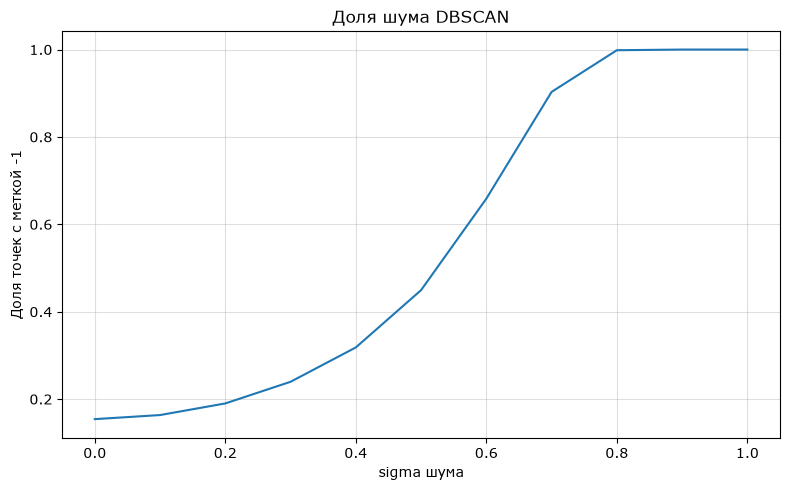

In [46]:
X_base = X.sample(n=min(15000, len(X)), random_state=SEED).to_numpy(dtype=float)
noise_sigmas = np.linspace(0.0, 1.0, 11)
noise_fractions = []

# Генерируем случайные отклонения один раз. Для каждого σ используем
# те же отклонения, чтобы сравнивать эффект их величины.
noise_rng = np.random.default_rng(SEED)
standard_noise = noise_rng.standard_normal(X_base.shape)

for sigma in noise_sigmas:
    # Каждый раз добавляем шум к исходному X, поэтому он не накапливается.
    X_noisy = X_base + sigma * standard_noise

    # Фиксируем параметры DBSCAN, чтобы менять только уровень шума.
    noisy_labels = DBSCAN(
        eps=db_eps,
        min_samples=db_min_samples,
        metric="euclidean",
    ).fit_predict(X_noisy)

    # DBSCAN помечает шум меткой -1. Среднее булевой маски даёт долю таких точек.
    noise_fractions.append(np.mean(noisy_labels == -1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(noise_sigmas, noise_fractions)
ax.set_title("Доля шума DBSCAN")
ax.set_xlabel(f"sigma шума")
ax.set_ylabel("Доля точек с меткой -1")
ax.grid(alpha=0.4)
fig.tight_layout()
plt.show()

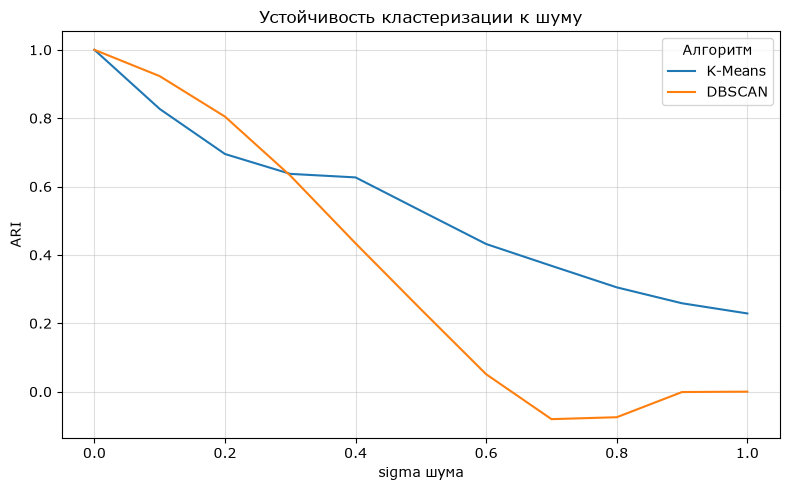

In [51]:
from sklearn.metrics import adjusted_rand_score

X_base = X.sample(n=min(35000, len(X)), random_state=SEED).to_numpy(dtype=float)
noise_sigmas = np.linspace(0.0, 1.0, 11)
noise_rng = np.random.default_rng(SEED)
standard_noise = noise_rng.standard_normal(X_base.shape)

# Фиксируем параметры обоих алгоритмов на всех уровнях шума.
models = {
    "K-Means": KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=SEED,
    ),
    "DBSCAN": DBSCAN(
        eps=db_eps,
        min_samples=db_min_samples,
        metric="euclidean",
    ),
}

# Каждый алгоритм получает своё эталонное разбиение без добавленного шума.
baseline_labels = {
    name: model.fit_predict(X_base)
    for name, model in models.items()
}

# При σ = 0 разбиение сравнивается с самим собой, поэтому ARI равен 1.
ari_scores = {name: [1.0] for name in models}

for sigma in noise_sigmas[1:]:
    # Оба алгоритма получают одни и те же возмущённые данные.
    # При каждом σ начинаем с исходной подвыборки.
    X_noisy = X_base + sigma * standard_noise

    for name, model in models.items():
        noisy_labels = model.fit_predict(X_noisy)

        # ARI сравнивает состав кластеров независимо от номеров меток.
        # Для DBSCAN метка -1 участвует в расчёте как отдельная группа.
        ari_scores[name].append(
            adjusted_rand_score(baseline_labels[name], noisy_labels)
        )

fig, ax = plt.subplots(figsize=(8, 5))

for name, scores in ari_scores.items():
    ax.plot(noise_sigmas, scores, label=name)

ax.set_title("Устойчивость кластеризации к шуму")
ax.set_xlabel(f"sigma шума")
ax.set_ylabel("ARI")
ax.legend(title="Алгоритм")
ax.grid(alpha=0.4)
fig.tight_layout()
plt.show()

### PCA для DBSCAN

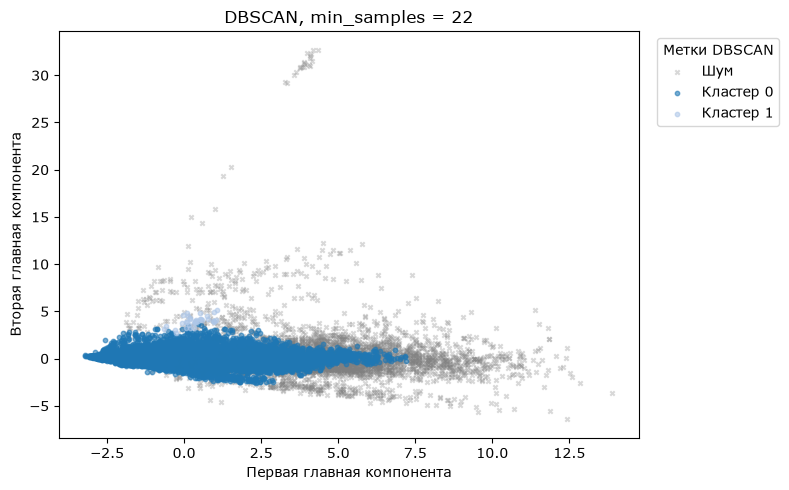

In [70]:
labels_db = dbscan_labels[db_min_samples]
X_db_2d = PCA(n_components=2).fit_transform(X)
noise = labels_db == -1

plt.figure(figsize=(8, 5))
plt.scatter(
    X_db_2d[noise, 0], X_db_2d[noise, 1],
    color="gray", marker="x", s=10, alpha=0.3, label="Шум",
)
# Для каждого кластера задаём свой цвет и подпись в легенде.
cmap = plt.get_cmap("tab20")
for i, cluster in enumerate(np.unique(labels_db[~noise])):
    mask = labels_db == cluster
    plt.scatter(
        X_db_2d[mask, 0], X_db_2d[mask, 1],
        color=cmap(i % cmap.N), s=10, alpha=0.6,
        label=f"Кластер {cluster}",
    )

plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title(f"DBSCAN, min_samples = {db_min_samples}")
plt.legend(title="Метки DBSCAN", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# Иерархическая кластеризация

In [71]:
def hierarchical_row(X_eval, y_true, metric, linkage, n_clusters=2):
    # Строим разбиение с заданной метрикой и способом связи.
    labels = AgglomerativeClustering(
        n_clusters=n_clusters,
        metric=metric,
        linkage=linkage,
    ).fit_predict(X_eval)

    # Считаем силуэт в той же метрике, в которой строили кластеры.
    silhouette = silhouette_score(X_eval, labels, metric=metric)

    # Сопоставляем реальные классы с объектами по индексу.
    # Для ARI берём только строки с известным AQI_Bucket.
    y_eval = y_true.loc[X_eval.index]
    known = y_eval.notna().to_numpy()
    ari = (
        adjusted_rand_score(y_eval[known], labels[known])
        if known.sum() >= 2
        else np.nan
    )

    # Доля кластера — его размер, делённый на размер всей подвыборки.
    shares = np.bincount(labels, minlength=n_clusters) / len(labels)

    row = {
        "Метрика": metric,
        "Linkage": linkage,
        "Silhouette": silhouette,
        "ARI": ari,
    }
    for cluster, share in enumerate(shares):
        row[f"Доля кластера {cluster}"] = share

    return row

In [72]:
X_hier = X.sample(n=min(3000, len(X)), random_state=42)

metrics = ["euclidean", "manhattan", "cosine"]
linkages = ["single", "average", "complete", "ward"]
rows = []

for metric in metrics:
    for linkage in linkages:
        # Метод Уорда поддерживает только евклидово расстояние.
        if linkage == "ward" and metric != "euclidean":
            continue

        rows.append(
            hierarchical_row(
                X_hier,
                y_true,
                metric=metric,
                linkage=linkage,
                n_clusters=3,
            )
        )

hierarchical_table = pd.DataFrame(rows)
print(hierarchical_table.round(6).to_string(index=False))

  Метрика  Linkage  Silhouette       ARI  Доля кластера 0  Доля кластера 1  Доля кластера 2
euclidean   single    0.643872  0.000582         0.999333         0.000333         0.000333
euclidean  average    0.662486  0.000293         0.999333         0.000333         0.000333
euclidean complete    0.548250  0.046487         0.940333         0.004667         0.055000
euclidean     ward    0.258465  0.191706         0.153333         0.246333         0.600333
manhattan   single    0.604012  0.000295         0.999333         0.000333         0.000333
manhattan  average    0.575047  0.006704         0.990667         0.000667         0.008667
manhattan complete    0.516765  0.122583         0.146000         0.848667         0.005333
   cosine   single   -0.051624 -0.000476         0.999333         0.000333         0.000333
   cosine  average    0.353270  0.163351         0.610000         0.359667         0.030333
   cosine complete    0.314643  0.123464         0.199333         0.232333      

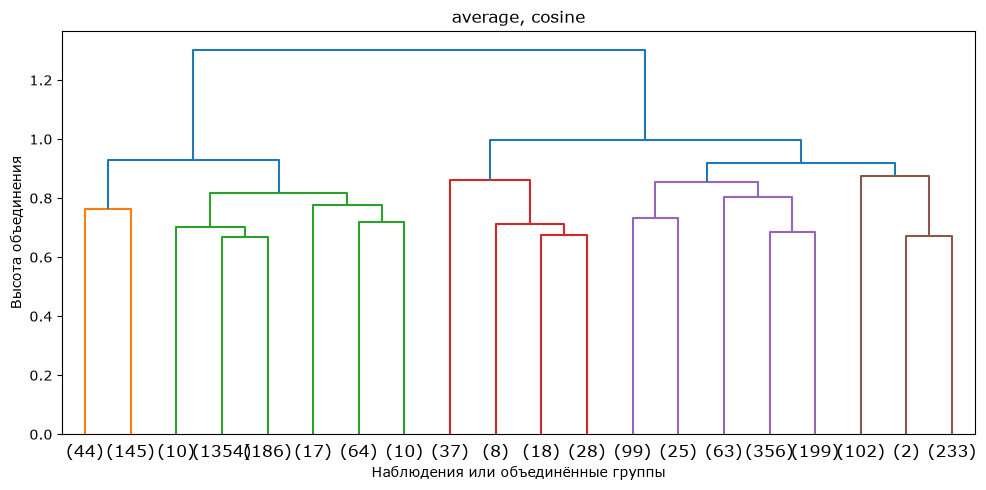

In [73]:
from scipy.cluster.hierarchy import dendrogram, linkage as scipy_linkage

# Выбираем метрику и способ связи.
hier_metric = "cosine"
hier_method = "average"
X_hier = X.sample(n=min(3000, len(X)), random_state=42)

# Для манхэттенского расстояния SciPy использует имя cityblock.
scipy_metric = "cityblock" if hier_metric == "manhattan" else hier_metric

# Берём до 3000 строк из того же набора, по которому выбираем индексы.
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(X_hier),
    size=min(3000, len(X_hier)),
    replace=False,
)
X_dendro = np.asarray(X_hier, dtype=float)[sample_idx]

# Строим полное дерево последовательных объединений на подвыборке.
tree = scipy_linkage(X_dendro, method=hier_method, metric=scipy_metric)

fig, ax = plt.subplots(figsize=(10, 5))

# Показываем верхнюю часть дерева с 20 группами на нижней оси.
dendrogram(tree, truncate_mode="lastp", p=20, ax=ax)

ax.set_title(f"{hier_method}, {hier_metric}")
ax.set_xlabel("Наблюдения или объединённые группы")
ax.set_ylabel("Высота объединения")
fig.tight_layout()
plt.show()

In [76]:
from scipy.cluster.hierarchy import fcluster

cut_height = 0.99

# Разрезаем выбранное дерево на заданной высоте.
# Получаем одну метку кластера для каждой строки X_dendro.
hierarchy_labels = fcluster(tree, t=cut_height, criterion="distance")

# Считаем количество объектов в каждом кластере.
sizes = pd.Series(hierarchy_labels).value_counts()

display(pd.DataFrame([{
    "Метрика": hier_metric,
    "Linkage": hier_method,
    "Высота разреза": cut_height,
    "Число кластеров": len(sizes),
    "Размеры кластеров": sizes.tolist(),
}]))

,Метрика,Linkage,Высота разреза,Число кластеров,Размеры кластеров
0,cosine,average,0.99,3,"[1830, 1079, 91]"


Метод связи,average,complete,single,ward
Строк,,,,
500,0.0039,0.0041,0.0026,0.0042
1000,0.0177,0.0197,0.0104,0.0198
2000,0.0716,0.0807,0.0411,0.0869
3000,0.3219,0.3464,0.1374,0.2050
5000,0.5064,0.4768,0.2289,0.5294
10000,2.9531,3.6883,1.1455,3.5826


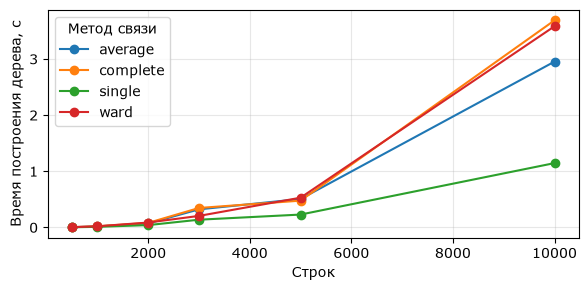

In [80]:
from time import perf_counter
from scipy.cluster.hierarchy import linkage as scipy_linkage

timings = []

for size in [500, 1000, 2000, 3000, 5000, 10000]:
    if size > len(X):
        continue

    # Для всех способов связи при данном размере берём одни и те же строки.
    X_size = X.iloc[:size].to_numpy(dtype=float)

    for method in linkages:
        # Замеряем только построение дерева. Медиана трёх запусков
        # уменьшает влияние случайных задержек.
        elapsed = []
        for _ in range(3):
            start = perf_counter()
            scipy_linkage(X_size, method=method, metric="euclidean")
            elapsed.append(perf_counter() - start)

        timings.append({
            "Строк": size,
            "Метод связи": method,
            "Секунды": np.median(elapsed),
        })

# Строки таблицы — размеры выборки, столбцы — способы связи.
time_table = pd.DataFrame(timings).pivot(
    index="Строка" if False else "Строк", columns="Метод связи", values="Секунды"
)
display(time_table.round(4))

ax = time_table.plot(marker="o", figsize=(7, 4))
ax.set_ylabel("Время построения дерева, с")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

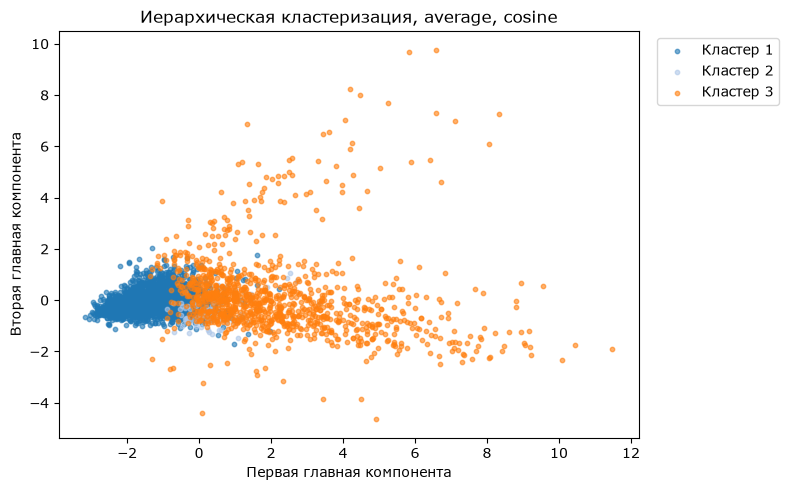

In [81]:
# PCA переводит строки X_dendro в две координаты для графика.
labels_hier_plot = hierarchy_labels
X_hier_2d = PCA(n_components=2).fit_transform(X_dendro)

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("tab20")

# Рисуем каждый кластер отдельно, чтобы он получил свой пункт в легенде.
for i, cluster in enumerate(np.unique(labels_hier_plot)):
    mask = labels_hier_plot == cluster
    ax.scatter(
        X_hier_2d[mask, 0], X_hier_2d[mask, 1],
        color=cmap(i % cmap.N), s=10, alpha=0.6,
        label=f"Кластер {cluster}",
    )

ax.set_xlabel("Первая главная компонента")
ax.set_ylabel("Вторая главная компонента")
ax.set_title(f"Иерархическая кластеризация, {hier_method}, {hier_metric}")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
plt.show()

# Построить дендрограмму для наиболее лучших сочетаний метрик и методов связи. Для этого возьмем подвыборку из 3000 объектов.